In [ ]:
"""
Investigation 1: Understand the Dataset
StayEase Booking Analytics Dataset
"""

import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

# ---------------------------------------------------------
# 1. Load dataset
# ---------------------------------------------------------
df = pd.read_csv("/content/StayEase_Cleaned_Dataset.csv")

print("=" * 70)
print("1. DATASET OVERVIEW")
print("=" * 70)
print(f"Number of records (rows): {df.shape[0]}")
print(f"Number of attributes (columns): {df.shape[1]}")
print(f"Arrival years covered: {sorted(df['arrival_year'].unique())}")



1. DATASET OVERVIEW
Number of records (rows): 102658
Number of attributes (columns): 37
Arrival years covered: [np.int64(2015), np.int64(2016), np.int64(2017)]


In [ ]:

# ---------------------------------------------------------
# 2. Attribute classification
# ---------------------------------------------------------
print("\n" + "=" * 70)
print("2. ATTRIBUTE DATA TYPES")
print("=" * 70)
print(df.dtypes)



2. ATTRIBUTE DATA TYPES
hotel_type                         object
booking_status                      int64
advance_booking_days                int64
arrival_year                        int64
arrival_month                      object
arrival_week                        int64
arrival_day                         int64
weekend_nights                      int64
weekday_nights                      int64
num_adults                          int64
num_children                      float64
num_infants                         int64
meal_plan                          object
guest_country                      object
booking_segment                    object
booking_channel                    object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room                      object
assigned_room                      object
modifications                       int64
deposit_type                       object
travel_ag

In [ ]:
categorical_cols = ['hotel_type', 'meal_plan', 'guest_country', 'booking_segment',
                     'booking_channel', 'reserved_room', 'assigned_room', 'deposit_type',
                     'customer_category', 'reservation_status', 'booking_season']
temporal_cols = ['arrival_year', 'arrival_month', 'arrival_week', 'arrival_day', 'reservation_date']
binary_cols = ['booking_status', 'is_repeated_guest', 'family_booking', 'is_long_stay']
numeric_cols = ['advance_booking_days', 'weekend_nights', 'weekday_nights', 'num_adults',
                 'num_children', 'num_infants', 'previous_cancellations',
                 'previous_bookings_not_canceled', 'modifications', 'waiting_days',
                 'parking_spaces', 'special_requests', 'total_stay_nights', 'total_guests',
                 'avg_daily_rate']
identifier_cols = ['travel_agent_id', 'corporate_id']

print(f"\nCategorical attributes ({len(categorical_cols)}): {categorical_cols}")
print(f"Temporal attributes ({len(temporal_cols)}): {temporal_cols}")
print(f"Binary/flag attributes ({len(binary_cols)}): {binary_cols}")
print(f"Numeric attributes ({len(numeric_cols)}): {numeric_cols}")
print(f"Identifier attributes ({len(identifier_cols)}): {identifier_cols}")



Categorical attributes (11): ['hotel_type', 'meal_plan', 'guest_country', 'booking_segment', 'booking_channel', 'reserved_room', 'assigned_room', 'deposit_type', 'customer_category', 'reservation_status', 'booking_season']
Temporal attributes (5): ['arrival_year', 'arrival_month', 'arrival_week', 'arrival_day', 'reservation_date']
Binary/flag attributes (4): ['booking_status', 'is_repeated_guest', 'family_booking', 'is_long_stay']
Numeric attributes (15): ['advance_booking_days', 'weekend_nights', 'weekday_nights', 'num_adults', 'num_children', 'num_infants', 'previous_cancellations', 'previous_bookings_not_canceled', 'modifications', 'waiting_days', 'parking_spaces', 'special_requests', 'total_stay_nights', 'total_guests', 'avg_daily_rate']
Identifier attributes (2): ['travel_agent_id', 'corporate_id']


In [ ]:
# ---------------------------------------------------------
# 3. Missing value summary
# ---------------------------------------------------------
print("\n" + "=" * 70)
print("3. MISSING VALUES SUMMARY")
print("=" * 70)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
print(missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_count', ascending=False))




3. MISSING VALUES SUMMARY
                 missing_count  missing_pct
travel_agent_id          16751        16.32


In [ ]:
# ---------------------------------------------------------
# 4. Duplicate records
# ---------------------------------------------------------
print("\n" + "=" * 70)
print("4. DUPLICATE RECORDS")
print("=" * 70)
dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count} ({dup_count/len(df)*100:.2f}% of dataset)")




4. DUPLICATE RECORDS
Duplicate rows: 13260 (12.92% of dataset)


In [ ]:
# ---------------------------------------------------------
# 5. Categorical consistency check
# ---------------------------------------------------------
print("\n" + "=" * 70)
print("5. CATEGORICAL VALUE INCONSISTENCIES (casing / spacing / spelling)")
print("=" * 70)
for col in ['hotel_type', 'booking_segment', 'booking_channel', 'customer_category',
            'meal_plan', 'deposit_type', 'reservation_status']:
    uniques = df[col].unique()
    print(f"\n{col} -> {len(uniques)} raw unique values:")
    print(sorted(uniques.tolist(), key=lambda x: str(x)))



5. CATEGORICAL VALUE INCONSISTENCIES (casing / spacing / spelling)

hotel_type -> 2 raw unique values:
['Luxury Resort', 'Urban Hotel']

booking_segment -> 8 raw unique values:
['Aviation', 'Complementary', 'Corporate', 'Direct', 'Group Bookings', 'Offline TA/TO', 'Online TA', 'Undefined']

booking_channel -> 5 raw unique values:
['Corporate', 'Direct', 'GDS', 'TA/TO', 'Undefined']

customer_category -> 4 raw unique values:
['Corporate Contract', 'Group Booking', 'Regular', 'Regular-Party']

meal_plan -> 5 raw unique values:
['FB', 'HB', 'SB', 'SC', 'Undefined']

deposit_type -> 3 raw unique values:
['No Deposit', 'Non Refund', 'Refundable']

reservation_status -> 3 raw unique values:
['Cancelled', 'Checked-Out', 'No-Show']


In [ ]:

# ---------------------------------------------------------
# 6. Descriptive statistics for numeric fields
# ---------------------------------------------------------
print("\n" + "=" * 70)
print("6. DESCRIPTIVE STATISTICS (numeric attributes)")
print("=" * 70)
print(df[numeric_cols].describe().T)



6. DESCRIPTIVE STATISTICS (numeric attributes)
                                   count        mean        std   min   25%   50%    75%    max
advance_booking_days            102658.0   91.751330  97.724257  0.00  14.0  58.0  142.0  737.0
weekend_nights                  102658.0    0.968147   1.012896  0.00   0.0   1.0    2.0   19.0
weekday_nights                  102658.0    2.546786   1.972881  0.00   1.0   2.0    3.0   50.0
num_adults                      102658.0    1.865067   0.491894  0.00   2.0   2.0    2.0    3.0
num_children                    102658.0    0.116513   0.418614  0.00   0.0   0.0    0.0   10.0
num_infants                     102658.0    0.009196   0.104699  0.00   0.0   0.0    0.0   10.0
previous_cancellations          102658.0    0.056732   0.620599  0.00   0.0   0.0    0.0   26.0
previous_bookings_not_canceled  102658.0    0.161458   1.633371  0.00   0.0   0.0    0.0   72.0
modifications                   102658.0    0.246011   0.690388  0.00   0.0   0.0    0.0

In [ ]:

# ---------------------------------------------------------
# 7. Target-like field distribution
# ---------------------------------------------------------
print("\n" + "=" * 70)
print("7. BOOKING STATUS DISTRIBUTION")
print("=" * 70)
print(df['booking_status'].value_counts())
print(df['booking_status'].value_counts(normalize=True).round(3) * 100)



7. BOOKING STATUS DISTRIBUTION
booking_status
0    69703
1    32955
Name: count, dtype: int64
booking_status
0    67.9
1    32.1
Name: proportion, dtype: float64


In [ ]:
"""
Investigation 2: Evaluate Data Readiness
StayEase Booking Analytics Dataset
"""

import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

df = pd.read_csv("/content/StayEase_Cleaned_Dataset.csv")


In [ ]:

def section(title):
    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)


# ================================================================
# 1. Numeric Outlier / Invalid Value Summary
# ================================================================
section("1. NUMERIC OUTLIER / INVALID VALUE SUMMARY")

numeric_check_cols = ['avg_daily_rate', 'total_stay_nights', 'num_adults', 'total_guests',
                       'advance_booking_days', 'weekend_nights', 'weekday_nights',
                       'num_children', 'num_infants', 'previous_cancellations',
                       'previous_bookings_not_canceled', 'modifications',
                       'waiting_days', 'parking_spaces', 'special_requests']

stats_table = pd.DataFrame({
    'min': df[numeric_check_cols].min(),
    'median': df[numeric_check_cols].median(),
    'p99': df[numeric_check_cols].quantile(0.99),
    'max': df[numeric_check_cols].max(),
    'negative_count': [(df[c] < 0).sum() for c in numeric_check_cols]
}).round(2)
print(stats_table)

section("2. SPECIFIC INVALID VALUE CHECKS")
invalid_checks = pd.DataFrame({
    'Check': [
        'avg_daily_rate <= 0',
        'num_adults = 0',
        '0 adults but children/infants present'
    ],
    'Count': [
        (df['avg_daily_rate'] <= 0).sum(),
        (df['num_adults'] == 0).sum(),
        ((df['num_adults'] == 0) & ((df['num_children'] > 0) | (df['num_infants'] > 0))).sum()
    ]
})
print(invalid_checks.to_string(index=False))



1. NUMERIC OUTLIER / INVALID VALUE SUMMARY
                                 min  median     p99    max  negative_count
avg_daily_rate                  0.26    98.0  255.91  256.5               0
total_stay_nights               0.00     3.0   14.00   69.0               0
num_adults                      0.00     2.0    3.00    3.0               0
total_guests                    0.00     2.0    4.00    4.0               0
advance_booking_days            0.00    58.0  408.00  737.0               0
weekend_nights                  0.00     1.0    4.00   19.0               0
weekday_nights                  0.00     2.0   10.00   50.0               0
num_children                    0.00     0.0    2.00   10.0               0
num_infants                     0.00     0.0    0.00   10.0               0
previous_cancellations          0.00     0.0    1.00   26.0               0
previous_bookings_not_canceled  0.00     0.0    4.00   72.0               0
modifications                   0.00     0.0

In [ ]:

# ================================================================
# 3. ID / Reference Field Sanity Check
# ================================================================
section("3. ID & REFERENCE FIELD SANITY CHECK")
print(f"travel_agent_id range : {df['travel_agent_id'].min()} to {df['travel_agent_id'].max()}")
print(f"corporate_id range    : {df['corporate_id'].min()} to {df['corporate_id'].max()}")
print(f"arrival_month values  : {sorted(df['arrival_month'].unique().tolist())}")
print("Status: No irregularities found in ID ranges or month labels.")


3. ID & REFERENCE FIELD SANITY CHECK
travel_agent_id range : 1.0 to 535.0
corporate_id range    : 10.0 to Not Applicable
arrival_month values  : ['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']
Status: No irregularities found in ID ranges or month labels.


In [ ]:

# ================================================================
# 4. Duplicate Impact on Key Business Metric
# ================================================================
section("4. DUPLICATE RECORDS — IMPACT ON CANCELLATION RATE")
dup_count = df.duplicated().sum()
rate_with = df['booking_status'].mean()
rate_without = df.drop_duplicates()['booking_status'].mean()

dup_table = pd.DataFrame({
    'Metric': ['Duplicate rows', 'Duplicate %', 'Cancellation rate (with duplicates)',
               'Cancellation rate (without duplicates)', 'Absolute shift'],
    'Value': [dup_count, f"{dup_count/len(df)*100:.2f}%", f"{rate_with:.4f}",
              f"{rate_without:.4f}", f"{abs(rate_with-rate_without):.4f}"]
})
print(dup_table.to_string(index=False))



4. DUPLICATE RECORDS — IMPACT ON CANCELLATION RATE
                                Metric  Value
                        Duplicate rows  13260
                           Duplicate % 12.92%
   Cancellation rate (with duplicates) 0.3210
Cancellation rate (without duplicates) 0.2847
                        Absolute shift 0.0363


In [ ]:
# ================================================================
# 5. Cross-Field Logical Consistency
# ================================================================
section("5. CROSS-FIELD LOGICAL CONSISTENCY CHECK")
consistency_table = pd.DataFrame({
    'Check': ['total_stay_nights = weekend_nights + weekday_nights',
              'total_guests = num_adults + num_children + num_infants'],
    'Mismatches': [
        (df['weekend_nights'] + df['weekday_nights'] != df['total_stay_nights']).sum(),
        (df['num_adults'] + df['num_children'].fillna(0) + df['num_infants'] != df['total_guests']).sum()
    ]
})
print(consistency_table.to_string(index=False))


5. CROSS-FIELD LOGICAL CONSISTENCY CHECK
                                                 Check  Mismatches
   total_stay_nights = weekend_nights + weekday_nights           0
total_guests = num_adults + num_children + num_infants         212


In [ ]:
# ================================================================
# 6. Date Logic Check
# ================================================================
section("6. RESERVATION DATE LOGIC CHECK")
df['reservation_date_parsed'] = pd.to_datetime(df['reservation_date'], format='%d-%m-%Y', errors='coerce')
date_table = pd.DataFrame({
    'Check': ['Unparseable reservation dates', 'Reservation booked AFTER arrival year (logical error)'],
    'Count': [
        df['reservation_date_parsed'].isnull().sum(),
        (df['reservation_date_parsed'].dt.year > df['arrival_year']).sum()
    ]
})
print(date_table.to_string(index=False))


6. RESERVATION DATE LOGIC CHECK
                                                Check  Count
                        Unparseable reservation dates      0
Reservation booked AFTER arrival year (logical error)      0


In [ ]:

# ================================================================
# 7. Categorical Standardization — Naive Cleanup (Insufficient)
# ================================================================
section("7. CATEGORICAL STANDARDIZATION — NAIVE CLEANUP (INSUFFICIENT)")
cat_cols = ['hotel_type', 'reservation_status', 'deposit_type',
            'meal_plan', 'booking_segment', 'booking_channel', 'customer_category']

naive_table = pd.DataFrame({
    'Column': cat_cols,
    'Raw variants': [df[c].nunique() for c in cat_cols],
    'After naive lower/strip': [df[c].str.strip().str.lower().nunique() for c in cat_cols]
})
print(naive_table.to_string(index=False))


7. CATEGORICAL STANDARDIZATION — NAIVE CLEANUP (INSUFFICIENT)
            Column  Raw variants  After naive lower/strip
        hotel_type             2                        2
reservation_status             3                        3
      deposit_type             3                        3
         meal_plan             5                        5
   booking_segment             8                        8
   booking_channel             5                        5
 customer_category             4                        4


In [ ]:

# ================================================================
# 8. Categorical Standardization — Explicit Mapping (Proper Treatment)
# ================================================================
section("8. CATEGORICAL STANDARDIZATION — EXPLICIT MAPPING (PROPER TREATMENT)")

deposit_map = {'no deposit': 'No Deposit', 'no-deposit': 'No Deposit',
               'non refund': 'Non Refund', 'non-refund': 'Non Refund',
               'refundable': 'Refundable', 'refund-able': 'Refundable'}
status_map = {'canceled': 'Cancelled', 'cancelled': 'Cancelled',
              'check-out': 'Checked-Out', 'checkout': 'Checked-Out',
              'no-show': 'No-Show', 'no show': 'No-Show'}
meal_map = {'sb': 'SB', 's.b.': 'SB', 'sc': 'SC', 's.c.': 'SC',
            'hb': 'HB', 'h.b.': 'HB', 'fb': 'FB', 'f.b.': 'FB', 'undefined': 'Undefined'}
segment_map = {'online ta': 'Online TA', 'online-ta': 'Online TA', 'offline ta/to': 'Offline TA/TO',
               'direct': 'Direct', 'group bookings': 'Group Bookings', 'group-bookings': 'Group Bookings',
               'corporate': 'Corporate', 'complementary': 'Complementary',
               'aviation': 'Aviation', 'undefined': 'Undefined'}
channel_map = {'ta/to': 'TA/TO', 'ta / to': 'TA/TO', 'direct': 'Direct',
               'corporate': 'Corporate', 'gds': 'GDS', 'g.d.s.': 'GDS', 'undefined': 'Undefined'}
cust_map = {'regular': 'Regular', 'regular-party': 'Regular-Party',
            'corporate contract': 'Corporate Contract', 'group booking': 'Group Booking'}

df['deposit_type_clean'] = df['deposit_type'].str.strip().str.lower().map(deposit_map)
df['reservation_status_clean'] = df['reservation_status'].str.strip().str.lower().map(status_map)
df['meal_plan_clean'] = df['meal_plan'].str.strip().str.lower().map(meal_map)
df['booking_segment_clean'] = df['booking_segment'].str.strip().str.lower().map(segment_map)
df['booking_channel_clean'] = df['booking_channel'].str.strip().str.lower().map(channel_map)
df['customer_category_clean'] = df['customer_category'].str.strip().str.lower().map(cust_map)

clean_cols = ['deposit_type_clean', 'reservation_status_clean', 'meal_plan_clean',
              'booking_segment_clean', 'booking_channel_clean', 'customer_category_clean']

mapping_table = pd.DataFrame({
    'Column': clean_cols,
    'Clean categories': [df[c].nunique() for c in clean_cols],
    'Unmapped (null) values': [df[c].isnull().sum() for c in clean_cols]
})
print(mapping_table.to_string(index=False))

section("DATA READINESS EVALUATION COMPLETE")


8. CATEGORICAL STANDARDIZATION — EXPLICIT MAPPING (PROPER TREATMENT)
                  Column  Clean categories  Unmapped (null) values
      deposit_type_clean                 3                       0
reservation_status_clean                 2                   69703
         meal_plan_clean                 5                       0
   booking_segment_clean                 8                       0
   booking_channel_clean                 5                       0
 customer_category_clean                 4                       0

DATA READINESS EVALUATION COMPLETE


In [ ]:
"""
Investigation 3: Prepare the Dataset
StayEase Booking Analytics Dataset — Preprocessing Pipeline
"""

import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

df = pd.read_csv("/content/StayEase_Cleaned_Dataset.csv")
before = len(df)

# A running log of every action taken, so the final summary is clean
# instead of scattered print statements.
log = []

In [ ]:

# ------------------------------------------------------------
# 1. Remove exact duplicate records
# ------------------------------------------------------------
n_before = len(df)
df = df.drop_duplicates()
log.append(["1. Exact duplicate rows", "Removed", n_before - len(df)])

In [ ]:

# ------------------------------------------------------------
# 2. Fix invalid avg_daily_rate (<=0) -> impute by hotel_type median
# ------------------------------------------------------------
adr_invalid = int((df['avg_daily_rate'] <= 0).sum())
df.loc[df['avg_daily_rate'] <= 0, 'avg_daily_rate'] = None
df['avg_daily_rate'] = df['avg_daily_rate'].fillna(
    df.groupby('hotel_type')['avg_daily_rate'].transform('median'))
log.append(["2. avg_daily_rate <= 0", "Imputed (hotel_type median)", adr_invalid])


In [ ]:

# ------------------------------------------------------------
# 3. Cap extreme avg_daily_rate highs at 99th percentile
# ------------------------------------------------------------
p99_adr = df['avg_daily_rate'].quantile(0.99)
capped_high = int((df['avg_daily_rate'] > p99_adr).sum())
df['avg_daily_rate'] = df['avg_daily_rate'].clip(upper=p99_adr)
log.append([f"3. avg_daily_rate > p99 ({p99_adr:.2f})", "Capped", capped_high])

In [ ]:
# ------------------------------------------------------------
# 4. Missing-value imputation (context-specific, per column)
# ------------------------------------------------------------
# 4a. guest_country — categorical, no info available -> "Unknown"
gc_missing = int(df['guest_country'].isnull().sum())
df['guest_country'] = df['guest_country'].fillna('Unknown')
log.append(["4a. guest_country missing", "Imputed ('Unknown')", gc_missing])

# 4b. agent_id — categorical identifier, absence means no agent involved -> "Not Applicable"
if 'agent_id' in df.columns:
    agent_missing = int(df['agent_id'].isnull().sum())
    df['agent_id'] = df['agent_id'].fillna('Not Applicable')
    log.append(["4b. agent_id missing", "Imputed ('Not Applicable')", agent_missing])

# 4c. corporate_id — categorical identifier, absence means no corporate account -> "Not Applicable"
if 'corporate_id' in df.columns:
    corp_missing = int(df['corporate_id'].isnull().sum())
    df['corporate_id'] = df['corporate_id'].fillna('Not Applicable')
    log.append(["4c. corporate_id missing", "Imputed ('Not Applicable')", corp_missing])

# 4d. num_children — numerical, logical default of 0 (no children recorded -> assume none)
if 'num_children' in df.columns:
    children_missing = int(df['num_children'].isnull().sum())
    df['num_children'] = df['num_children'].fillna(0)
    log.append(["4d. num_children missing", "Imputed (0)", children_missing])

In [ ]:
# ------------------------------------------------------------
# 5. Remove logically invalid num_adults = 0 with minors present
# ------------------------------------------------------------
n_before = len(df)
df = df[~((df['num_adults'] == 0) & ((df['num_children'] > 0) | (df['num_infants'] > 0)))]
log.append(["5. num_adults=0 with minors present", "Removed", n_before - len(df)])


In [ ]:
# ------------------------------------------------------------
# 6. Cap extreme guest-count outliers
# ------------------------------------------------------------
p99_guests = df['total_guests'].quantile(0.99)
capped_guests = int((df['total_guests'] > p99_guests).sum())
df['total_guests'] = df['total_guests'].clip(upper=p99_guests)
df['num_adults'] = df['num_adults'].clip(upper=df['num_adults'].quantile(0.99))
log.append([f"6. total_guests/num_adults > p99 ({p99_guests:.1f})", "Capped", capped_guests])

In [ ]:
# ------------------------------------------------------------
# 7. Remove reservation-date logic errors
# ------------------------------------------------------------
n_before = len(df)
df['reservation_date_parsed'] = pd.to_datetime(df['reservation_date'], format='%d-%m-%Y', errors='coerce')
bad_dates = int((df['reservation_date_parsed'].dt.year > df['arrival_year']).sum())
df = df[~(df['reservation_date_parsed'].dt.year > df['arrival_year'])]
log.append(["7. Reservation date after arrival year", "Removed", n_before - len(df)])


In [ ]:

# ------------------------------------------------------------
# 8. Standardize categorical columns via explicit mapping
# ------------------------------------------------------------
hotel_map = {'luxury resort': 'Luxury Resort', 'urban hotel': 'Urban Hotel'}
deposit_map = {'no deposit': 'No Deposit', 'no-deposit': 'No Deposit',
               'non refund': 'Non Refund', 'non-refund': 'Non Refund',
               'refundable': 'Refundable', 'refund-able': 'Refundable'}
status_map = {'canceled': 'Cancelled', 'cancelled': 'Cancelled',
              'check-out': 'Checked-Out', 'checkout': 'Checked-Out',
              'no-show': 'No-Show', 'no show': 'No-Show'}
meal_map = {'sb': 'SB', 's.b.': 'SB', 'sc': 'SC', 's.c.': 'SC',
            'hb': 'HB', 'h.b.': 'HB', 'fb': 'FB', 'f.b.': 'FB', 'undefined': 'Undefined'}
segment_map = {'online ta': 'Online TA', 'online-ta': 'Online TA', 'offline ta/to': 'Offline TA/TO',
               'direct': 'Direct', 'group bookings': 'Group Bookings', 'group-bookings': 'Group Bookings',
               'corporate': 'Corporate', 'complementary': 'Complementary',
               'aviation': 'Aviation', 'undefined': 'Undefined'}
channel_map = {'ta/to': 'TA/TO', 'ta / to': 'TA/TO', 'direct': 'Direct',
               'corporate': 'Corporate', 'gds': 'GDS', 'g.d.s.': 'GDS', 'undefined': 'Undefined'}
cust_map = {'regular': 'Regular', 'regular-party': 'Regular-Party',
            'corporate contract': 'Corporate Contract', 'group booking': 'Group Booking'}

df['hotel_type'] = df['hotel_type'].str.strip().str.lower().map(hotel_map)
df['deposit_type'] = df['deposit_type'].str.strip().str.lower().map(deposit_map)
df['reservation_status'] = df['reservation_status'].str.strip().str.lower().map(status_map)
df['meal_plan'] = df['meal_plan'].str.strip().str.lower().map(meal_map)
df['booking_segment'] = df['booking_segment'].str.strip().str.lower().map(segment_map)
df['booking_channel'] = df['booking_channel'].str.strip().str.lower().map(channel_map)
df['customer_category'] = df['customer_category'].str.strip().str.lower().map(cust_map)

cat_cols = ['hotel_type', 'deposit_type', 'reservation_status', 'meal_plan',
            'booking_segment', 'booking_channel', 'customer_category']
post_std_nulls = int(df[cat_cols].isnull().sum().sum())
log.append(["8. Categorical standardization (7 cols)", "Remapped, remaining nulls", post_std_nulls])


In [ ]:
# ------------------------------------------------------------
# Clean summary table (replaces scattered print statements)
# ------------------------------------------------------------
summary_df = pd.DataFrame(log, columns=["Step", "Action", "Rows/Values Affected"])

print("=" * 70)
print("STAYEASE DATASET — CLEANING SUMMARY")
print("=" * 70)
print(summary_df.to_string(index=False))
print("-" * 70)
print(f"{'Original rows:':30s}{before:>10,}")
print(f"{'Final rows after cleaning:':30s}{len(df):>10,}")
print(f"{'Total rows removed:':30s}{before - len(df):>10,}  "
      f"({(before - len(df)) / before * 100:.2f}%)")
print("=" * 70)

df = df.drop(columns=['reservation_date_parsed'])
df.to_csv("StayEase_Cleaned_Dataset.csv", index=False)
print("Cleaned dataset saved as StayEase_Cleaned_Dataset.csv")

summary_df.to_csv("StayEase_Cleaning_Summary.csv", index=False)


STAYEASE DATASET — CLEANING SUMMARY
                                   Step                      Action  Rows/Values Affected
                1. Exact duplicate rows                     Removed                 13260
                 2. avg_daily_rate <= 0 Imputed (hotel_type median)                     0
       3. avg_daily_rate > p99 (256.50)                      Capped                     0
              4a. guest_country missing         Imputed ('Unknown')                     0
               4c. corporate_id missing  Imputed ('Not Applicable')                     0
               4d. num_children missing                 Imputed (0)                     0
    5. num_adults=0 with minors present                     Removed                     0
 6. total_guests/num_adults > p99 (4.0)                      Capped                     0
 7. Reservation date after arrival year                     Removed                     0
8. Categorical standardization (7 cols)   Remapped, remaining nu

In [ ]:
"""
Investigation 4: Customer Behaviour Analysis
StayEase Booking Analytics Dataset
"""

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_style("whitegrid")

df = pd.read_csv("StayEase_Cleaned_Dataset.csv")


Customer Category Distribution:
customer_category
Regular               73010
Regular-Party         12641
Corporate Contract     3204
Group Booking           543
Name: count, dtype: int64


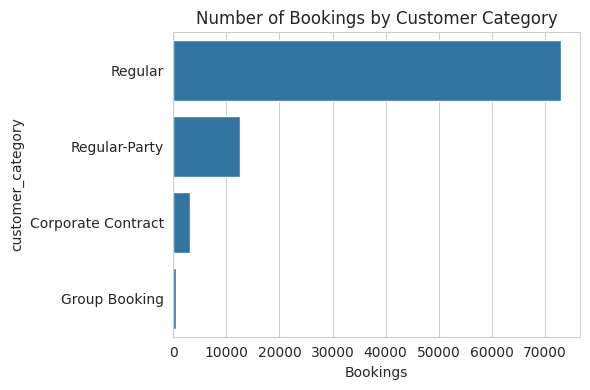

In [ ]:
# ------------------------------------------------------------
# 1. Customer category distribution
# ------------------------------------------------------------
print("Customer Category Distribution:")
print(df['customer_category'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, y='customer_category', order=df['customer_category'].value_counts().index)
plt.title("Number of Bookings by Customer Category")
plt.xlabel("Bookings")
plt.tight_layout()
plt.show()


Cancellation Rate (%) by Customer Category:
customer_category
Regular               29.93
Corporate Contract    16.85
Regular-Party         15.66
Group Booking          9.39
dtype: float64


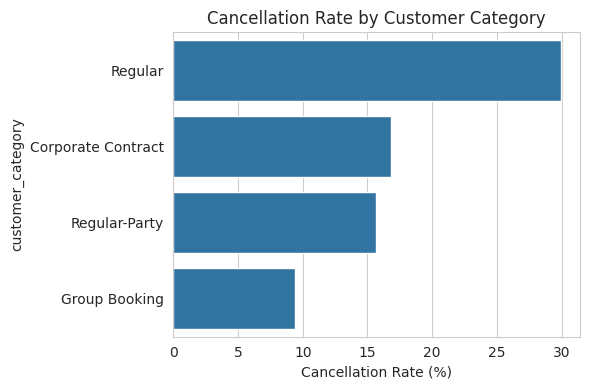


Chi-square test: chi2 = 25.33, p-value = 1.32e-05
Significant association


In [ ]:
# ------------------------------------------------------------
# 2. Cancellation rate by customer category
# ------------------------------------------------------------
cancel_rate = (df[df['reservation_status'] == 'Cancelled']
               .groupby('customer_category').size() /
               df.groupby('customer_category').size() * 100).sort_values(ascending=False)

print("\nCancellation Rate (%) by Customer Category:")
print(cancel_rate.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(x=cancel_rate.values, y=cancel_rate.index)
plt.title("Cancellation Rate by Customer Category")
plt.xlabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

# Chi-square test: is customer_category associated with cancellation?
contingency = pd.crosstab(df['customer_category'], df['reservation_status'])
chi2, p, dof, exp = chi2_contingency(contingency)
print(f"\nChi-square test: chi2 = {chi2:.2f}, p-value = {p:.4g}")
print("Significant association" if p < 0.05 else "No significant association")



Average Daily Rate by Customer Category:
customer_category
Regular               110.65
Corporate Contract     93.10
Regular-Party          90.25
Group Booking          89.66
Name: avg_daily_rate, dtype: float64


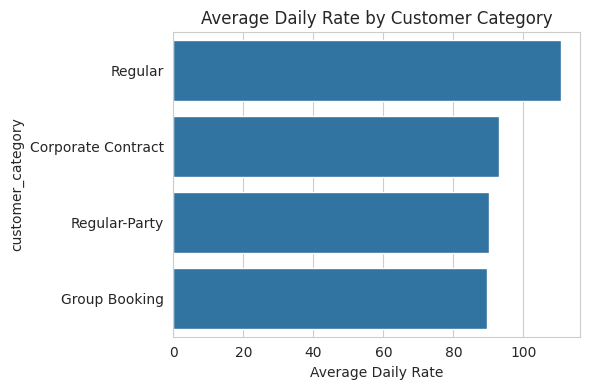

In [ ]:
# ------------------------------------------------------------
# 3. Average spend (ADR) by customer category
# ------------------------------------------------------------
adr_by_cat = df.groupby('customer_category')['avg_daily_rate'].mean().sort_values(ascending=False)
print("\nAverage Daily Rate by Customer Category:")
print(adr_by_cat.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(x=adr_by_cat.values, y=adr_by_cat.index)
plt.title("Average Daily Rate by Customer Category")
plt.xlabel("Average Daily Rate")
plt.tight_layout()
plt.show()


Top 10 Guest Countries:
guest_country
PRT        27630
GBR        10284
FRA         8641
ESP         7129
DEU         5348
Unknown     3310
ITA         3015
IRL         2967
BEL         2037
BRA         1929
Name: count, dtype: int64


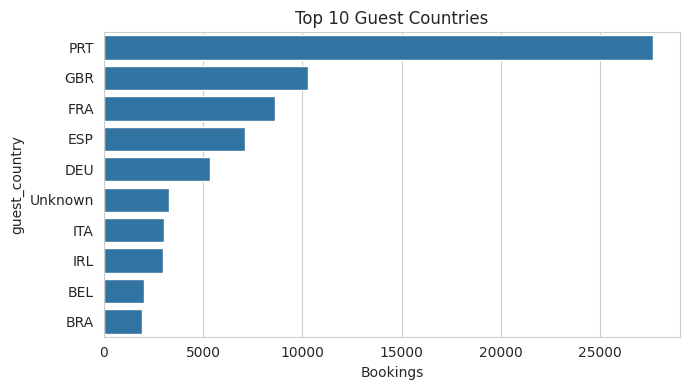

In [ ]:
# ------------------------------------------------------------
# 4. Guest country mix (top 10)
# ------------------------------------------------------------
top_countries = df['guest_country'].value_counts().head(10)
print("\nTop 10 Guest Countries:")
print(top_countries)

plt.figure(figsize=(7, 4))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Guest Countries")
plt.xlabel("Bookings")
plt.tight_layout()
plt.show()

In [ ]:

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("KEY FINDINGS")
print("=" * 60)
print(f"1. Most common customer category: {df['customer_category'].value_counts().idxmax()}")
print(f"2. Highest cancellation rate: {cancel_rate.index[0]} ({cancel_rate.iloc[0]:.1f}%)")
print(f"3. Chi-square p-value (category vs cancellation): {p:.4g} "
      f"({'significant' if p < 0.05 else 'not significant'})")
print(f"4. Highest-paying customer category: {adr_by_cat.index[0]} ({adr_by_cat.iloc[0]:.2f})")
print(f"5. Top guest country: {top_countries.index[0]} ({top_countries.iloc[0]} bookings)")


KEY FINDINGS
1. Most common customer category: Regular
2. Highest cancellation rate: Regular (29.9%)
3. Chi-square p-value (category vs cancellation): 1.32e-05 (significant)
4. Highest-paying customer category: Regular (110.65)
5. Top guest country: PRT (27630 bookings)


In [ ]:
"""
Investigation 5: Business Relationships
StayEase Booking Analytics Dataset
"""

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pearsonr, f_oneway

sns.set_style("whitegrid")

df = pd.read_csv("StayEase_Cleaned_Dataset.csv")

Cancellation Rate (%) by Booking Channel:
booking_channel
Undefined    80.00
TA/TO        30.96
GDS          18.13
Direct       13.65
Corporate    11.80
dtype: float64


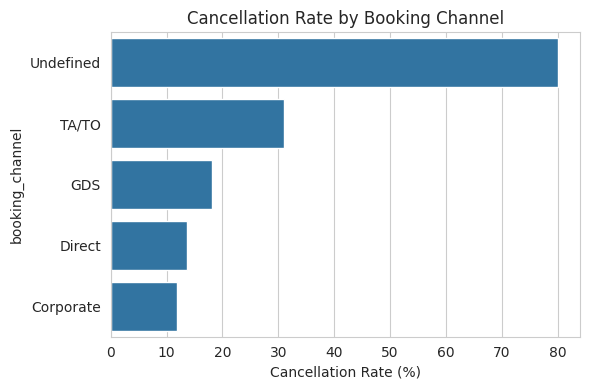


Chi-square test (channel vs cancellation): chi2 = 340.37, p-value = 2.102e-72
Significant association


In [ ]:

# ------------------------------------------------------------
# 1. Booking Channel vs Cancellation
# ------------------------------------------------------------
channel_cancel = (df[df['reservation_status'] == 'Cancelled']
                  .groupby('booking_channel').size() /
                  df.groupby('booking_channel').size() * 100).sort_values(ascending=False)

print("Cancellation Rate (%) by Booking Channel:")
print(channel_cancel.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(x=channel_cancel.values, y=channel_cancel.index)
plt.title("Cancellation Rate by Booking Channel")
plt.xlabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

contingency = pd.crosstab(df['booking_channel'], df['reservation_status'])
chi2, p, dof, exp = chi2_contingency(contingency)
print(f"\nChi-square test (channel vs cancellation): chi2 = {chi2:.2f}, p-value = {p:.4g}")
print("Significant association" if p < 0.05 else "No significant association")


Cancellation Rate (%) by Deposit Type:
deposit_type
Non Refund    96.42
No Deposit    25.85
Refundable    22.52
dtype: float64


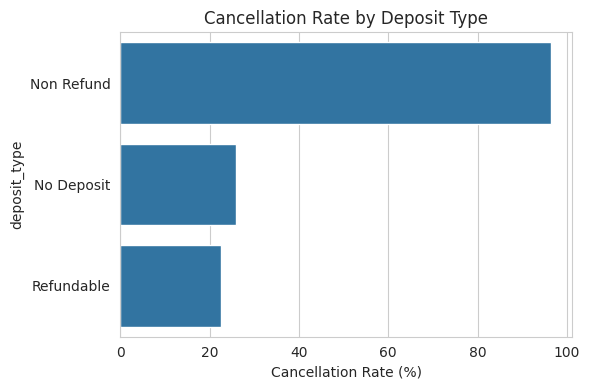


Chi-square test (deposit vs cancellation): chi2 = 63.34, p-value = 1.762e-14
Significant association


In [ ]:

# ------------------------------------------------------------
# 2. Deposit Type vs Cancellation
# ------------------------------------------------------------
deposit_cancel = (df[df['reservation_status'] == 'Cancelled']
                  .groupby('deposit_type').size() /
                  df.groupby('deposit_type').size() * 100).sort_values(ascending=False)

print("\nCancellation Rate (%) by Deposit Type:")
print(deposit_cancel.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(x=deposit_cancel.values, y=deposit_cancel.index)
plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

contingency2 = pd.crosstab(df['deposit_type'], df['reservation_status'])
chi2_2, p2, dof2, exp2 = chi2_contingency(contingency2)
print(f"\nChi-square test (deposit vs cancellation): chi2 = {chi2_2:.2f}, p-value = {p2:.4g}")
print("Significant association" if p2 < 0.05 else "No significant association")


Average Daily Rate by Hotel Type:
hotel_type
Urban Hotel      112.14
Luxury Resort     98.79
Name: avg_daily_rate, dtype: float64


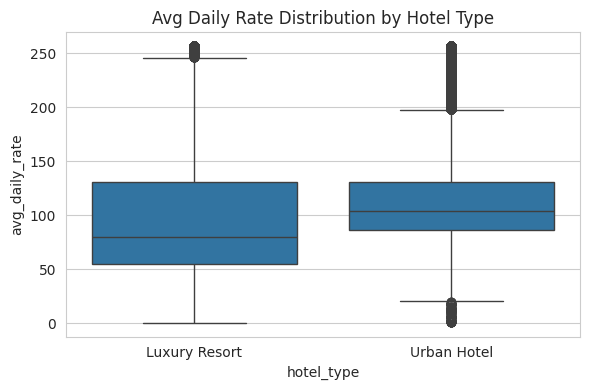


ANOVA test (hotel type vs ADR): F = 1707.23, p-value = 0
Significant difference


In [ ]:

# ------------------------------------------------------------
# 3. Hotel Type vs Average Daily Rate
# ------------------------------------------------------------
adr_by_hotel = df.groupby('hotel_type')['avg_daily_rate'].mean().sort_values(ascending=False)
print("\nAverage Daily Rate by Hotel Type:")
print(adr_by_hotel.round(2))

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='hotel_type', y='avg_daily_rate')
plt.title("Avg Daily Rate Distribution by Hotel Type")
plt.tight_layout()
plt.show()

groups = [g['avg_daily_rate'].values for _, g in df.groupby('hotel_type')]
f_stat, p3 = f_oneway(*groups)
print(f"\nANOVA test (hotel type vs ADR): F = {f_stat:.2f}, p-value = {p3:.4g}")
print("Significant difference" if p3 < 0.05 else "No significant difference")


Average Daily Rate by Booking Segment:
booking_segment
Online TA         117.78
Direct            116.39
Aviation          102.54
Complementary      91.95
Offline TA/TO      83.91
Group Bookings     79.31
Corporate          70.35
Undefined          15.00
Name: avg_daily_rate, dtype: float64


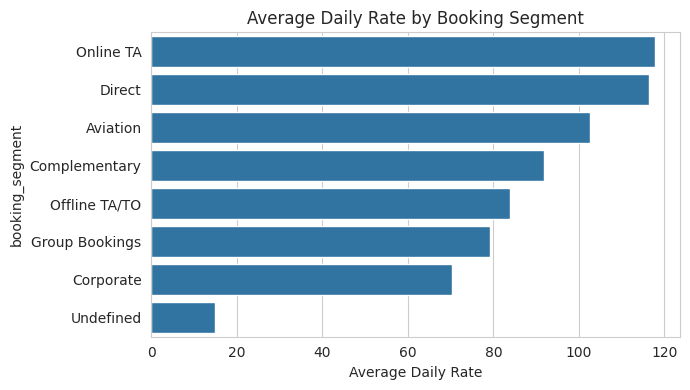

In [ ]:
# ------------------------------------------------------------
# 4. Booking Segment vs Average Daily Rate
# ------------------------------------------------------------
adr_by_segment = df.groupby('booking_segment')['avg_daily_rate'].mean().sort_values(ascending=False)
print("\nAverage Daily Rate by Booking Segment:")
print(adr_by_segment.round(2))

plt.figure(figsize=(7, 4))
sns.barplot(x=adr_by_segment.values, y=adr_by_segment.index)
plt.title("Average Daily Rate by Booking Segment")
plt.xlabel("Average Daily Rate")
plt.tight_layout()
plt.show()


Bookings by Arrival Month:
arrival_month
January       4787
February      6244
March         7682
April         8157
May           8664
June          8015
July         10299
August       11482
September     7005
October       7304
November      5139
December      4620
Name: count, dtype: int64

Average Daily Rate by Arrival Month:
arrival_month
January       73.20
February      77.28
March         83.04
April        104.49
May          111.80
June         119.99
July         134.35
August       148.24
September    112.74
October       92.80
November      76.06
December      79.87
Name: avg_daily_rate, dtype: float64


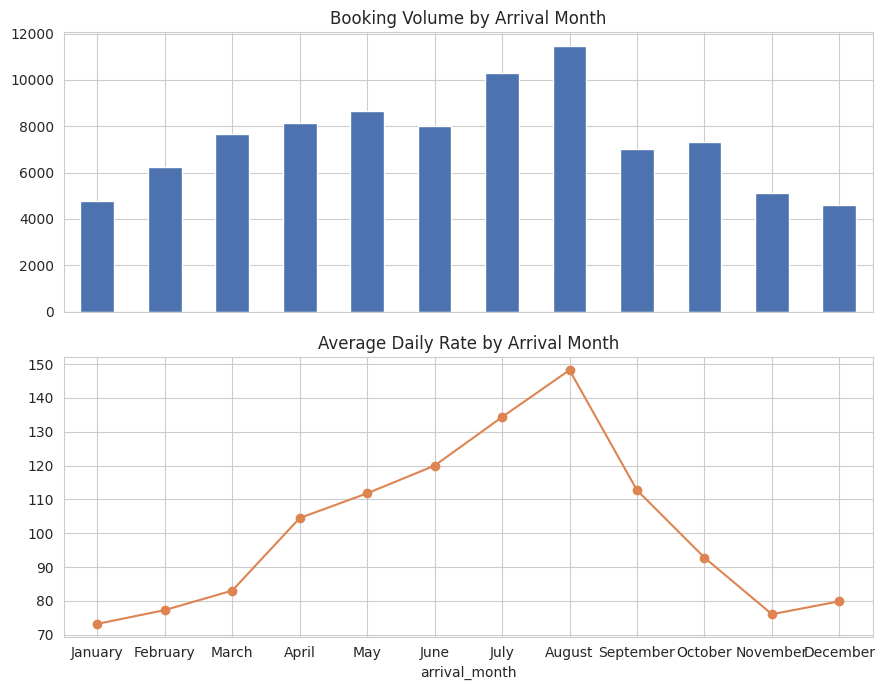


Correlation between monthly booking volume and monthly ADR: r = 0.91, p-value = 3.756e-05


In [ ]:
# ------------------------------------------------------------
# 5. Seasonal Demand: Arrival Month vs Booking Volume & ADR
# ------------------------------------------------------------
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
present_months = [m for m in month_order if m in df['arrival_month'].unique()]

monthly_bookings = df['arrival_month'].value_counts().reindex(present_months)
monthly_adr = df.groupby('arrival_month')['avg_daily_rate'].mean().reindex(present_months)

print("\nBookings by Arrival Month:")
print(monthly_bookings)
print("\nAverage Daily Rate by Arrival Month:")
print(monthly_adr.round(2))

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
monthly_bookings.plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title("Booking Volume by Arrival Month")
monthly_adr.plot(kind='line', marker='o', ax=axes[1], color='#DD8452')
axes[1].set_title("Average Daily Rate by Arrival Month")
plt.tight_layout()
plt.show()

corr_month, p4 = pearsonr(monthly_bookings.values, monthly_adr.values)
print(f"\nCorrelation between monthly booking volume and monthly ADR: r = {corr_month:.2f}, p-value = {p4:.4g}")

In [ ]:
# ------------------------------------------------------------
# 6. Room Allocation: Requested vs Assigned Room Type Mismatch
# ------------------------------------------------------------
if 'reserved_room_type' in df.columns and 'assigned_room_type' in df.columns:
    mismatch = (df['reserved_room_type'] != df['assigned_room_type']).mean() * 100
    print(f"\nRoom reallocation rate (assigned != reserved): {mismatch:.2f}%")

    mismatch_cancel = df.groupby(df['reserved_room_type'] != df['assigned_room_type'])['reservation_status'].apply(
        lambda s: (s == 'Cancelled').mean() * 100)
    print("\nCancellation Rate (%) by Room Reallocation:")
    print(mismatch_cancel.round(2))

    plt.figure(figsize=(5, 4))
    sns.barplot(x=['Same Room', 'Reallocated'], y=mismatch_cancel.values)
    plt.title("Cancellation Rate: Same Room vs Reallocated Room")
    plt.ylabel("Cancellation Rate (%)")
    plt.tight_layout()
    plt.show()


In [ ]:

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("KEY FINDINGS")
print("=" * 60)
print(f"1. Highest-cancelling channel: {channel_cancel.index[0]} ({channel_cancel.iloc[0]:.1f}%), "
      f"chi2 p-value = {p:.4g}")
print(f"2. Highest-cancelling deposit type: {deposit_cancel.index[0]} ({deposit_cancel.iloc[0]:.1f}%), "
      f"chi2 p-value = {p2:.4g}")
print(f"3. Highest-ADR hotel type: {adr_by_hotel.index[0]} ({adr_by_hotel.iloc[0]:.2f}), "
      f"ANOVA p-value = {p3:.4g}")
print(f"4. Highest-ADR booking segment: {adr_by_segment.index[0]} ({adr_by_segment.iloc[0]:.2f})")
print(f"5. Peak booking month: {monthly_bookings.idxmax()}, "
      f"correlation between volume and ADR: r = {corr_month:.2f}")



KEY FINDINGS
1. Highest-cancelling channel: Undefined (80.0%), chi2 p-value = 2.102e-72
2. Highest-cancelling deposit type: Non Refund (96.4%), chi2 p-value = 1.762e-14
3. Highest-ADR hotel type: Urban Hotel (112.14), ANOVA p-value = 0
4. Highest-ADR booking segment: Online TA (117.78)
5. Peak booking month: August, correlation between volume and ADR: r = 0.91


In [ ]:
"""
Investigation 6: Quantify Business Impact
StayEase Booking Analytics Dataset
"""

import pandas as pd

df = pd.read_csv("StayEase_Cleaned_Dataset.csv")
cancelled = df[df['reservation_status'] == 'Cancelled']

In [ ]:
# ------------------------------------------------------------
# 1. Overall revenue at risk
# ------------------------------------------------------------
total_value = df['avg_daily_rate'].sum()
lost_value = cancelled['avg_daily_rate'].sum()

print("=" * 55)
print("OVERALL REVENUE AT RISK")
print("=" * 55)
print(f"Total bookings:              {len(df):,}")
print(f"Cancelled bookings:          {len(cancelled):,}")
print(f"Total booking value (ADR sum): {total_value:,.2f}")
print(f"Cancelled booking value:       {lost_value:,.2f}")
print(f"Share of value lost:           {lost_value / total_value * 100:.2f}%")

OVERALL REVENUE AT RISK
Total bookings:              89,398
Cancelled bookings:          24,421
Total booking value (ADR sum): 9,566,661.55
Cancelled booking value:       2,847,083.35
Share of value lost:           29.76%


In [ ]:
# ------------------------------------------------------------
# 2. Where the lost revenue is concentrated
# ------------------------------------------------------------
def impact_table(group_col):
    g = cancelled.groupby(group_col)['avg_daily_rate'].sum().sort_values(ascending=False)
    share = (g / lost_value * 100).round(2)
    out = pd.DataFrame({'Cancelled Revenue': g.round(2), 'Share of Total Loss (%)': share})
    return out

print("\n" + "=" * 55)
print("REVENUE AT RISK BY CUSTOMER CATEGORY")
print("=" * 55)
print(impact_table('customer_category'))

print("\n" + "=" * 55)
print("REVENUE AT RISK BY BOOKING CHANNEL")
print("=" * 55)
print(impact_table('booking_channel'))

print("\n" + "=" * 55)
print("REVENUE AT RISK BY DEPOSIT TYPE")
print("=" * 55)
print(impact_table('deposit_type'))


REVENUE AT RISK BY CUSTOMER CATEGORY
                    Cancelled Revenue  Share of Total Loss (%)
customer_category                                             
Regular                    2621237.98                    92.07
Regular-Party               168300.61                     5.91
Corporate Contract           51653.50                     1.81
Group Booking                 5891.26                     0.21

REVENUE AT RISK BY BOOKING CHANNEL
                 Cancelled Revenue  Share of Total Loss (%)
booking_channel                                            
TA/TO                   2577179.91                    90.52
Direct                   214946.19                     7.55
Corporate                 50907.05                     1.79
GDS                        3931.70                     0.14
Undefined                   118.50                     0.00

REVENUE AT RISK BY DEPOSIT TYPE
              Cancelled Revenue  Share of Total Loss (%)
deposit_type                          

In [ ]:

# ------------------------------------------------------------
# 3. Reference: cancellation RATE by deposit type
#    (shown alongside revenue impact so rate and rupee-value
#     don't get confused with each other)
# ------------------------------------------------------------
print("\n" + "=" * 55)
print("CANCELLATION RATE (%) BY DEPOSIT TYPE (for reference)")
print("=" * 55)
print((df[df['reservation_status'] == 'Cancelled'].groupby('deposit_type').size() /
       df.groupby('deposit_type').size() * 100).round(2))


CANCELLATION RATE (%) BY DEPOSIT TYPE (for reference)
deposit_type
No Deposit    25.85
Non Refund    96.42
Refundable    22.52
dtype: float64


In [ ]:
"""
Investigation 7: Recommend Business Actions - Supporting Calculations
StayEase Booking Analytics Dataset
"""

import pandas as pd

df = pd.read_csv("StayEase_Cleaned_Dataset.csv")
cancelled = df[df['reservation_status'] == 'Cancelled']
total_value = df['avg_daily_rate'].sum()


In [ ]:
# ------------------------------------------------------------
# 1. Impact of reducing No Deposit cancellations
# ------------------------------------------------------------
no_dep = df[df['deposit_type'] == 'No Deposit']
no_dep_cancel_rate = (no_dep['reservation_status'] == 'Cancelled').mean()
no_dep_lost_value = no_dep[no_dep['reservation_status'] == 'Cancelled']['avg_daily_rate'].sum()

print("=" * 55)
print("1. IMPACT: Reducing No Deposit cancellations")
print("=" * 55)
print(f"Current No Deposit cancellation rate: {no_dep_cancel_rate*100:.2f}%")
print(f"Current revenue lost from No Deposit cancels: {no_dep_lost_value:,.2f}")
for reduction in [0.05, 0.10, 0.20]:
    recovered = no_dep_lost_value * reduction
    print(f"  If cancellation rate drops by {reduction*100:.0f}%: recover ~{recovered:,.2f}")


1. IMPACT: Reducing No Deposit cancellations
Current No Deposit cancellation rate: 25.85%
Current revenue lost from No Deposit cancels: 2,682,527.98
  If cancellation rate drops by 5%: recover ~134,126.40
  If cancellation rate drops by 10%: recover ~268,252.80
  If cancellation rate drops by 20%: recover ~536,505.60


In [ ]:
# ------------------------------------------------------------
# 2. Impact of tightening TA/TO cancellation policy
# ------------------------------------------------------------
tato = df[df['booking_channel'] == 'TA/TO']
tato_lost_value = tato[tato['reservation_status'] == 'Cancelled']['avg_daily_rate'].sum()

print("\n" + "=" * 55)
print("2. IMPACT: Tightening TA/TO cancellation policy")
print("=" * 55)
print(f"Current revenue lost from TA/TO cancels: {tato_lost_value:,.2f}")
for reduction in [0.05, 0.10, 0.20]:
    recovered = tato_lost_value * reduction
    print(f"  If cancellation rate drops by {reduction*100:.0f}%: recover ~{recovered:,.2f}")



2. IMPACT: Tightening TA/TO cancellation policy
Current revenue lost from TA/TO cancels: 2,577,179.91
  If cancellation rate drops by 5%: recover ~128,859.00
  If cancellation rate drops by 10%: recover ~257,717.99
  If cancellation rate drops by 20%: recover ~515,435.98


In [ ]:
# ------------------------------------------------------------
# 3. Seasonal gap: revenue if off-peak months matched average ADR
# ------------------------------------------------------------
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
present_months = [m for m in month_order if m in df['arrival_month'].unique()]

monthly_adr = df.groupby('arrival_month')['avg_daily_rate'].mean().reindex(present_months)
monthly_bookings = df['arrival_month'].value_counts().reindex(present_months)
overall_avg_adr = df['avg_daily_rate'].mean()

off_peak = ['January', 'November', 'December']
off_peak = [m for m in off_peak if m in monthly_adr.index]

print("\n" + "=" * 55)
print("3. IMPACT: Off-season revenue gap (Jan/Nov/Dec)")
print("=" * 55)
for m in off_peak:
    current_revenue = monthly_adr[m] * monthly_bookings[m]
    potential_revenue = overall_avg_adr * monthly_bookings[m]
    gap = potential_revenue - current_revenue
    print(f"{m}: current ADR {monthly_adr[m]:.2f} vs overall avg {overall_avg_adr:.2f} "
          f"-> potential gap ~{gap:,.2f}")


3. IMPACT: Off-season revenue gap (Jan/Nov/Dec)
January: current ADR 73.20 vs overall avg 107.01 -> potential gap ~161,856.74
November: current ADR 76.06 vs overall avg 107.01 -> potential gap ~159,037.97
December: current ADR 79.87 vs overall avg 107.01 -> potential gap ~125,397.33


In [ ]:
# ------------------------------------------------------------
# 4. Regular customer segment: value + risk concentration
# ------------------------------------------------------------
reg = df[df['customer_category'] == 'Regular']
reg_share_bookings = len(reg) / len(df) * 100
reg_share_loss = (cancelled[cancelled['customer_category'] == 'Regular']['avg_daily_rate'].sum()
                  / cancelled['avg_daily_rate'].sum() * 100)

print("\n" + "=" * 55)
print("4. Regular customer concentration (value + risk)")
print("=" * 55)
print(f"Share of all bookings: {reg_share_bookings:.2f}%")
print(f"Share of all cancelled revenue: {reg_share_loss:.2f}%")


4. Regular customer concentration (value + risk)
Share of all bookings: 81.67%
Share of all cancelled revenue: 92.07%
